In [2]:
!pip install kagglehub


   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
  Attempting uninstall: certifi
   ---------------------------------------- 0/4 [tqdm]
    Found existing installation: certifi 2024.8.30
   ---------------------------------------- 0/4 [tqdm]
    Uninstalling certifi-2024.8.30:
   ---------------------------------------- 0/4 [tqdm]
      Successfully uninstalled certifi-2024.8.30
   ---------------------------------------- 0/4 [tqdm]
   ---------- ----------------------------- 1/4 [certifi]
   ---------- ----------------------------- 1/4 [certifi]
   -------------------- ------------------- 2/4 [kaggle


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import kagglehub
import os
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from keras.utils import set_random_seed
from keras.models import Sequential
from keras.layers import Dense, Flatten, Conv2D, MaxPool2D, Dropout, Input
from sklearn.utils import compute_class_weight
from keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay
import hashlib

C:\Users\noora\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Reading the data

In [4]:
# Download latest version
path = kagglehub.dataset_download("jangedoo/utkface-new")

print("Path to dataset files:", path)

100%|██████████| 331M/331M [02:36<00:00, 2.21MB/s] 

Extracting files...


Path to dataset files: C:\Users\noora\.cache\kagglehub\datasets\jangedoo\utkface-new\versions\1


In [5]:
# check what is inside the downloaded folder
os.listdir(path)

['crop_part1', 'UTKFace', 'utkface_aligned_cropped']

In [6]:
img_path = os.path.join(path, "UTKFace")

files = os.listdir(img_path)
len(files)

23708

In [7]:
files[:3]

['100_0_0_20170112213500903.jpg.chip.jpg',
 '100_0_0_20170112215240346.jpg.chip.jpg',
 '100_1_0_20170110183726390.jpg.chip.jpg']

In [8]:
# split every name by "_" and keep only the names that have all 4 parts
rows = []
for f in files:
    p = f.split("_")
    if len(p) == 4:
        rows.append(dict(file=f, age=int(p[0]), gender=int(p[1]), race=int(p[2])))

df = pd.DataFrame(rows)
df.shape

(23705, 4)

## Incpect the data

[age] is an integer from 0 to 116, indicating the age

[gender] is either 0 (male) or 1 (female)

[race] is an integer from 0 to 4, denoting White, Black, Asian, Indian, and Others (like Hispanic, Latino, Middle Eastern)

[date&time] is in the format of yyyymmddHHMMSSFFF, showing the date and time an image was collected to UTKFace

In [9]:
df.head()

,file,age,gender,race
0,100_0_0_20170112213500903.jpg.chip.jpg,100,0,0
1,100_0_0_20170112215240346.jpg.chip.jpg,100,0,0
2,100_1_0_20170110183726390.jpg.chip.jpg,100,1,0
3,100_1_0_20170112213001988.jpg.chip.jpg,100,1,0
4,100_1_0_20170112213303693.jpg.chip.jpg,100,1,0


In [10]:
# 0 (male) or 1 (female)
df["gender"].value_counts()

gender
0    12391
1    11314
Name: count, dtype: int64

In [11]:
df["race"].value_counts()

race
0    10078
1     4526
3     3975
2     3434
4     1692
Name: count, dtype: int64

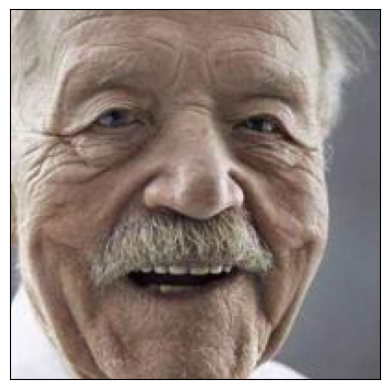

(200, 200)

In [12]:
# plot one image from the folder
img = Image.open(os.path.join(img_path, df.file[0]))
plt.imshow(img)
plt.xticks([])
plt.yticks([])
plt.show()
img.size

Creat the age groups


In [13]:
bins = [0, 12, 19, 29, 44, 59, 120]

df["age_group"] = pd.cut(df.age, bins=bins, labels=False)

class_names = ["0-12", "13-19", "20-29", "30-44", "45-59", "60+"]

df[["age", "age_group"]].head()

,age,age_group
0,100,5
1,100,5
2,100,5
3,100,5
4,100,5


In [14]:
df.age_group.value_counts().sort_index()

age_group
0    3413
1    1180
2    7344
3    5717
4    3363
5    2688
Name: count, dtype: int64

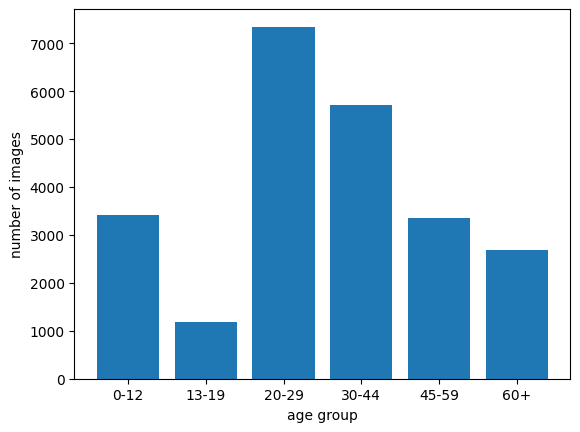

In [15]:
counts = df.age_group.value_counts().sort_index()

plt.bar(class_names, counts.values)
plt.xlabel("age group")
plt.ylabel("number of images")
plt.show()

In [ ]:
df["hash"] = [hashlib.md5(open(os.path.join(img_path, f), "rb").read()).hexdigest() for f in df.file]

g = df.groupby("hash").age.agg(["nunique", "size"])

conflict = g[(g["size"] > 1) & (g["nunique"] > 1)].index
df = df[~df.hash.isin(conflict)]

df = df.drop_duplicates("hash").reset_index(drop=True)

df.shape

In [ ]:
X = np.zeros((len(df), 64, 64, 3), dtype="uint8")

for i, f in enumerate(df.file):
    img = Image.open(os.path.join(img_path, f)).convert("RGB").resize((64, 64))
    X[i] = np.array(img)

y = df.age_group.values

X.shape, y.shape

## split the data

In [ ]:
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y,
                                                              test_size=0.2,
                                                              stratify=y)

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val,
                                                  test_size=0.2,
                                                  stratify=y_train_val)

In [ ]:
X_train_scaled = X_train / 255
X_val_scaled   = X_val / 255
X_test_scaled  = X_test / 255

## Model

In [ ]:
seed = 9999
set_random_seed(seed)

model = Sequential()

model.add(Input(shape=(64, 64, 3)))

model.add(Conv2D(filters=30, kernel_size=(3, 3), activation='relu'))
model.add(MaxPool2D(pool_size=(2, 2)))
model.add(Conv2D(filters=40, kernel_size=3, activation='relu'))

model.add(Flatten())

model.add(Dense(100, activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(6, activation='softmax'))


model.summary()

Assign weights

In [ ]:
c_weights = compute_class_weight(class_weight="balanced",
                                 classes=np.unique(y_train), y=y_train)

In [ ]:
class_weight_dict = dict(zip(np.unique(y_train), c_weights))
class_weight_dict

fit and compile

In [ ]:
model.compile(loss='sparse_categorical_crossentropy',
              optimizer='adam',
              metrics=['acc'])

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(X_train_scaled, y_train,
                    validation_data=(X_val_scaled, y_val),
                    epochs=20,
                    batch_size=32,
                    shuffle=False,
                    class_weight=class_weight_dict,
                    callbacks=[early_stop])

In [ ]:
history_df = pd.DataFrame(history.history)
history_df

In [ ]:
history_df[['acc', 'val_acc']].plot();

### test with the test

In [ ]:
y_pred_test_prob = model.predict(X_test_scaled)
y_pred_test_prob.max()

In [ ]:
model.evaluate(X_test_scaled, y_test)

confusion matrix

In [ ]:
y_pred_test_prob = model.predict(X_test_scaled)

y_pred_test = y_pred_test_prob.argmax(axis=1)
y_pred_test

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, display_labels=class_names, xticks_rotation='vertical');

In [ ]:
np.unique(y)

# deployment

In [ ]:
model.save("age_model.keras")

In [ ]:
from google.colab import files
files.download("age_model.keras")